# Hành trình training FPT: bằng chứng, so sánh và cải thiện

## Tóm tắt
Notebook đọc kết quả đã lưu; **không tải giá, không train model, không thay model serving**. Các biểu đồ chia theo giao thức: tái lập CPU–Colab, robustness trên Yahoo, đổi nguồn với nhãn Vietcap, training window, rồi phân tích lỗi/Ridge refinement. Không nối các RMSE khác nhãn/cohort thành một đường “accuracy tăng”.

Mọi kết quả là nghiên cứu hồi cứu; 2025 và khoảng 2026 đến 29/10 đã được xem. Phần 10 là recency/bias; phần 11–12 gom nhánh phân loại và gap/thân nến. API hiện dùng Ridge6+bias; tên LSTM serving trong bảng cũ là vai trò lịch sử. Chưa chứng minh hiệu quả giao dịch hoặc khả năng dự báo ở giai đoạn tương lai.

**Điểm cần nhớ:** CPU–Colab xác minh khả năng tái lập; audit đã tìm bất đồng nguồn; đổi nguồn/window/regularization chỉ cải thiện một số trường hợp. Baseline vẫn mạnh. Phần 6 là window; phần 7–8 là phân tích lỗi/Ridge. Lựa chọn theo validation, giữ cả kết quả evaluation kém hơn.

## Phương pháp và nguồn
- Target: log-return ở quan sát hợp lệ kế tiếp. RMSE/MAE càng thấp càng tốt; MSE skill > 0 là vượt Zero Return trên cùng nhãn.
- Mean-fold: trung bình không trọng số từng fold; seed SD là biến động training, **không phải confidence interval**.
- CPU/Colab: `reports/training_history/`; robustness: `reports/robustness/20261029T131205702813Z/`.
- Đối chứng nguồn: `reports/source_comparison/20261029T142732805710Z/`. Vietcap là nguồn tham chiếu, chưa chứng nhận point-in-time/lịch HOSE.
- Study window mới đọc từ chỉ mục `reports/window_comparison/studies.json`; chỉ lấy study `complete`.

Mở notebook từ root project hoặc thư mục notebooks. Cần môi trường Python của project; không cần weights để xem các kết quả đã lưu.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/source_comparison_v1.json').exists())
SC = ROOT/'reports/source_comparison/20261029T142732805710Z'
RB = ROOT/'reports/robustness/20261029T131205702813Z'
QA = ROOT/'.cache/training-journey-qa'
QA.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.5), 'font.size': 11, 'axes.grid': True, 'grid.alpha': .18, 'figure.dpi': 110})
def show(name):
    plt.tight_layout()
    plt.savefig(QA/(name+'.png'), dpi=130, bbox_inches='tight')
    plt.show()
read = lambda p: pd.read_csv(p)
timeline = read(ROOT/'reports/training_history/run_timeline.csv')
historical = read(ROOT/'reports/training_history/metrics_over_runs.csv')
source = read(SC/'seed_stability.csv')
primary = read(SC/'primary_summary.csv')
display(Markdown(f"**Nguồn:** {ROOT.name}. Notebook dùng file kết quả, không gọi API thị trường."))

**Nguồn:** Stock_Prediction_Project. Notebook dùng file kết quả, không gọi API thị trường.

## 1. Các giai đoạn đã làm
Biểu đồ này là mốc công việc, không biểu diễn hiệu quả dự báo. Bản legacy trước review chỉ có metadata và đã khác giao thức, nên không xếp hạng trực tiếp với v2.

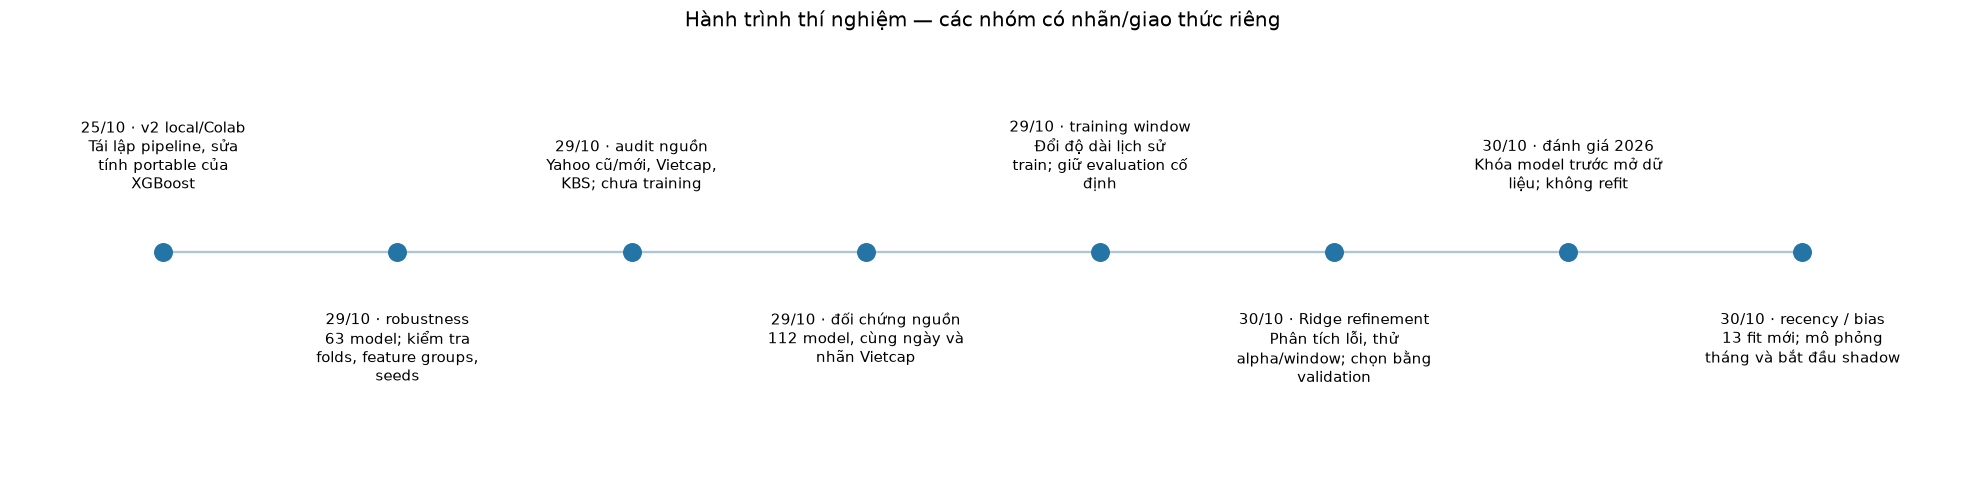

In [2]:
stages = [
 ('25/10 · v2 local/Colab', 'Tái lập pipeline, sửa tính portable của XGBoost'),
 ('29/10 · robustness', '63 model; kiểm tra folds, feature groups, seeds'),
 ('29/10 · audit nguồn', 'Yahoo cũ/mới, Vietcap, KBS; chưa training'),
 ('29/10 · đối chứng nguồn', '112 model, cùng ngày và nhãn Vietcap'),
 ('29/10 · training window', 'Đổi độ dài lịch sử train; giữ evaluation cố định'),
 ('30/10 · Ridge refinement', 'Phân tích lỗi, thử alpha/window; chọn bằng validation'),
 ('30/10 · đánh giá 2026', 'Khóa model trước mở dữ liệu; không refit'),
 ('30/10 · recency / bias', '13 fit mới; mô phỏng tháng và bắt đầu shadow')]
fig, ax = plt.subplots(figsize=(18, 4.5))
for i, (label, detail) in enumerate(stages):
    ax.scatter(i, 0, s=130, color='#2474a6')
    ax.text(i, .13 if i%2==0 else -.13, label+'\n'+textwrap.fill(detail,24), ha='center', va='bottom' if i%2==0 else 'top', fontsize=10)
ax.plot(range(len(stages)), np.zeros(len(stages)), color='#aac6d7', zorder=0)
ax.set_ylim(-.48,.48); ax.set_xlim(-.65,len(stages)-.35); ax.axis('off')
ax.set_title('Hành trình thí nghiệm — các nhóm có nhãn/giao thức riêng')
show('01_stages')

### Bản legacy trước review
Chỉ có metadata, không có hash dataset/predictions để chứng minh cùng nhãn và cohort. Bảng này giữ lịch sử, không dùng để tính phần trăm cải thiện so với v2.

In [3]:
legacy=json.loads((ROOT/'reports/training_history/evidence/legacy_metadata.json').read_text())['metadata']
display(pd.DataFrame({'lookback':[legacy['lookback']], 'epochs thực chạy':[legacy['epochs_trained']],
                      'val RMSE (legacy)':[legacy['validation_metrics']['rmse']],
                      'test RMSE (legacy)':[legacy['test_metrics']['rmse']]}).round(7))

,lookback,epochs thực chạy,val RMSE (legacy),test RMSE (legacy)
0,60,17,0.014085,0.02004


## 2. CPU–Colab: kiểm tra tái lập
Cùng snapshot Yahoo, cùng split và cấu hình. Đây là kiểm tra portability/determinism; các lượt gần trùng nhau không chứng minh accuracy tăng sau mỗi lần train.

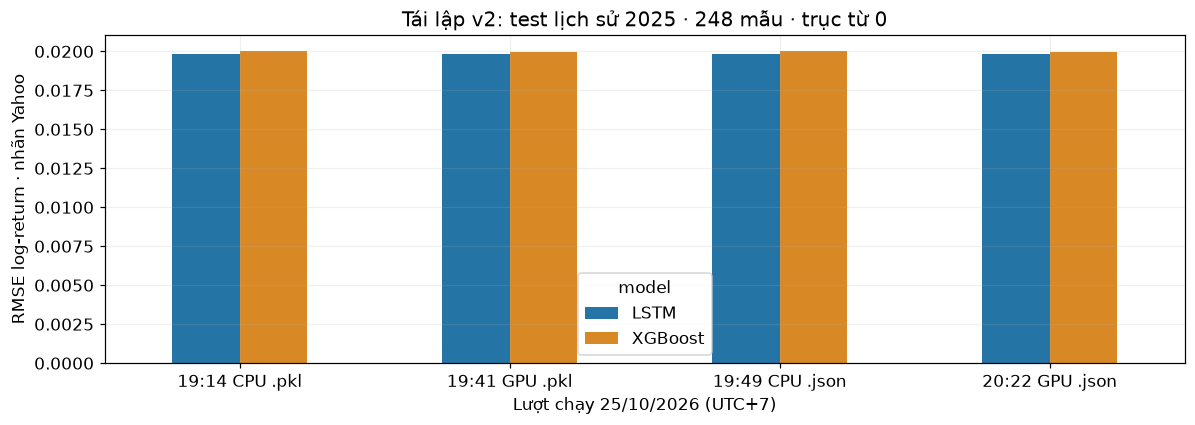

model,LSTM,XGBoost
run_id,,
20261025T121448987851Z,0.019858,0.020017
20261025T124129642764Z,0.019858,0.019939
20261025T124951351761Z,0.019858,0.020017
20261025T132243824425Z,0.019858,0.019939


LSTM gần như trùng nhau; XGBoost có sai khác môi trường nhỏ. Native JSON giải quyết chuyển model giữa Windows và Colab.

In [4]:
test = historical.query("split == 'test' and model in ['LSTM', 'XGBoost']")
table = test.pivot(index='run_id', columns='model', values='rmse').reindex(timeline.run_id)
labels = [f"{r.started_bangkok[11:16]} {r.device} {r.xgboost_format}" for r in timeline.itertuples()]
ax = table.plot.bar(figsize=(11,4), rot=0, color=['#2474a6','#d88926'])
ax.set_xticklabels(labels); ax.set_ylabel('RMSE log-return · nhãn Yahoo'); ax.set_xlabel('Lượt chạy 25/10/2026 (UTC+7)')
ax.set_title('Tái lập v2: test lịch sử 2025 · 248 mẫu · trục từ 0')
show('02_portability')
display(table.round(9))
display(Markdown('LSTM gần như trùng nhau; XGBoost có sai khác môi trường nhỏ. Native JSON giải quyết chuyển model giữa Windows và Colab.'))

## 3. Robustness ban đầu: nhiều fold, seed và nhóm feature
Vẫn dùng nhãn Yahoo. So sánh **trong đợt này**, không đối chiếu trị số RMSE với đợt dùng nhãn Vietcap phía dưới.

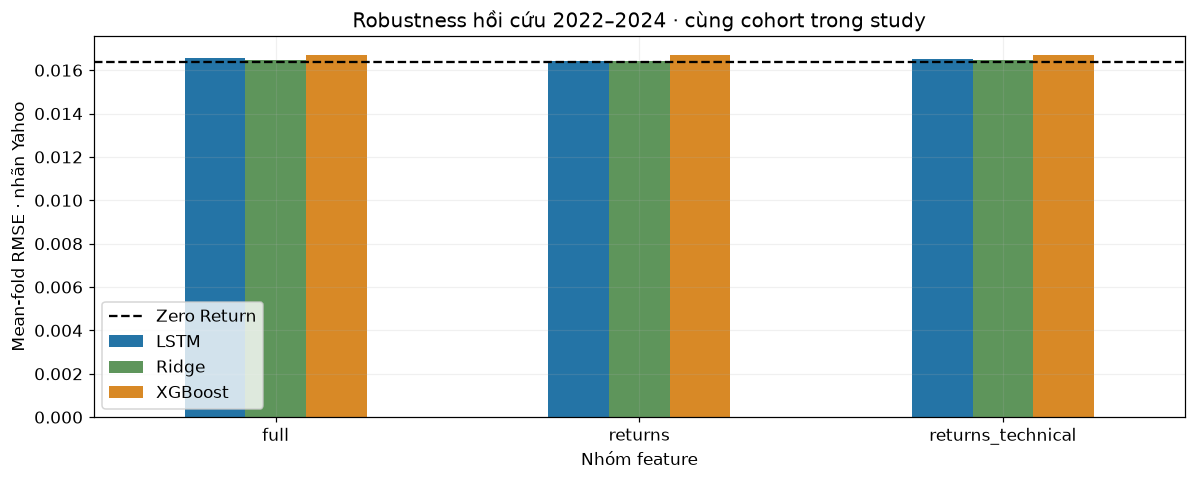

Các model học chưa vượt baseline nhất quán qua nhiều fold. Chỉ tăng số lần train chưa tạo được lợi thế ổn định.

In [5]:
robust = read(RB/'fold_summary.csv')
learned = robust[robust.model.isin(['Ridge','XGBoost','LSTM'])]
grid = learned.pivot(index='feature_group', columns='model', values='mean_fold_rmse')
ax = grid.plot.bar(rot=0, color=['#2474a6','#5e955b','#d88926'])
zero_old = robust.query("model == 'Zero-Return'").mean_fold_rmse.iloc[0]
ax.axhline(zero_old, color='black', linestyle='--', label='Zero Return')
ax.set_ylabel('Mean-fold RMSE · nhãn Yahoo'); ax.set_xlabel('Nhóm feature')
ax.set_title('Robustness hồi cứu 2022–2024 · cùng cohort trong study'); ax.legend()
show('03_robustness')
display(Markdown('Các model học chưa vượt baseline nhất quán qua nhiều fold. Chỉ tăng số lần train chưa tạo được lợi thế ổn định.'))

## 4. Đổi nguồn: Yahoo và Vietcap trên cùng nhãn đánh giá
Hai nhánh có cùng 1.791 origin–target pairs đủ context; cùng số labeled training rows mỗi fold. Train labels native; validation/evaluation đều dùng nhãn Vietcap. Context native có thể gồm các ngày khác nhau.

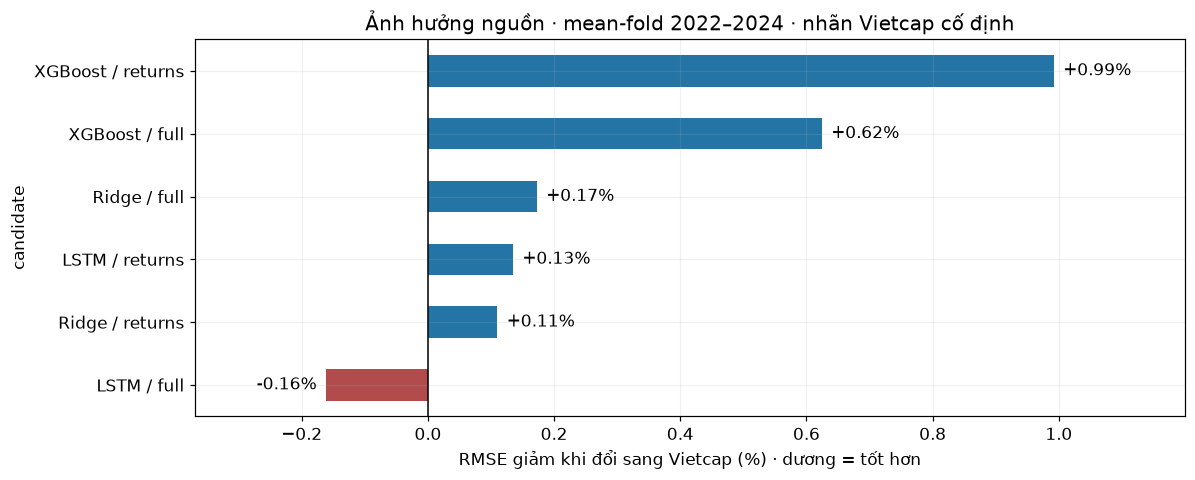

XGBoost returns cải thiện khoảng 0,99%; LSTM returns khoảng 0,13%; LSTM full kém hơn. Dữ liệu nhất quán hơn không bảo đảm mọi model đều tốt hơn.

In [6]:
paired = read(SC/'paired_fold_comparison.csv')
rows = []
for (group, model), p in primary[primary.feature_group!='baseline'].groupby(['feature_group','model']):
    y = p[p.source=='yahoo_v2'].iloc[0]; v = p[p.source=='vietcap_v3_candidate'].iloc[0]
    rows.append({'candidate': model+' / '+group, 'rmse_gain_pct': 100*(1-v.mean_fold_rmse/y.mean_fold_rmse)})
gains = pd.DataFrame(rows).set_index('candidate').sort_values('rmse_gain_pct')
ax = gains.rmse_gain_pct.plot.barh(color=['#b24c4c' if x<0 else '#2474a6' for x in gains.rmse_gain_pct])
ax.axvline(0,color='black',lw=1); ax.set_xlabel('RMSE giảm khi đổi sang Vietcap (%) · dương = tốt hơn')
ax.set_title('Ảnh hưởng nguồn · mean-fold 2022–2024 · nhãn Vietcap cố định')
for i,x in enumerate(gains.rmse_gain_pct): ax.text(x+(.015 if x>=0 else -.015),i,f'{x:+.2f}%',va='center',ha='left' if x>=0 else 'right')
ax.margins(x=.18); show('04_source_gain')
display(Markdown('XGBoost returns cải thiện khoảng 0,99%; LSTM returns khoảng 0,13%; LSTM full kém hơn. Dữ liệu nhất quán hơn không bảo đảm mọi model đều tốt hơn.'))

### Độ ổn định theo seed và baseline
Ridge chạy xác định một lần nên không gán seed SD bằng 0. SD dưới đây là trung bình SD qua ba fold, mỗi fold có ba seed.

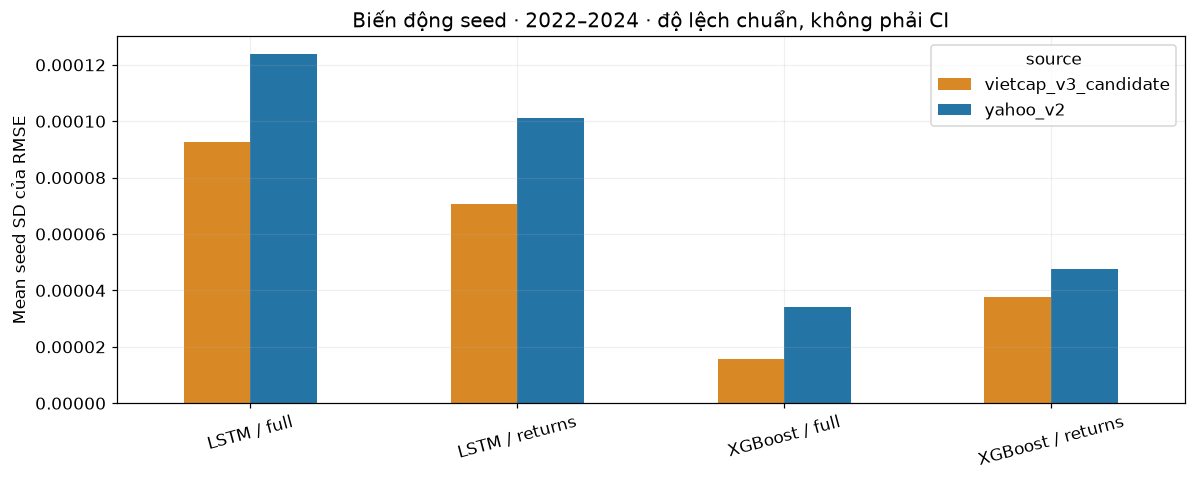

,source,feature_group,model,mean_fold_rmse,positive_skill_folds
0,shared,baseline,Zero-Return,0.016350,0
1,vietcap_v3_candidate,baseline,Return Persistence,0.022581,0
2,vietcap_v3_candidate,baseline,Train Mean,0.016292,2
3,vietcap_v3_candidate,full,LSTM,0.016522,1
4,vietcap_v3_candidate,full,Ridge,0.016395,1
5,vietcap_v3_candidate,full,XGBoost,0.016595,1
6,vietcap_v3_candidate,returns,LSTM,0.016395,1
7,vietcap_v3_candidate,returns,Ridge,0.016354,1
8,vietcap_v3_candidate,returns,XGBoost,0.016472,1
9,yahoo_v2,baseline,Return Persistence,0.022607,0


In [7]:
stochastic = primary[primary.model.isin(['LSTM','XGBoost'])].copy()
stochastic['candidate'] = stochastic.model+' / '+stochastic.feature_group
sd = stochastic.pivot(index='candidate',columns='source',values='mean_seed_std')
ax=sd.plot.bar(rot=15,color=['#d88926','#2474a6']); ax.set_ylabel('Mean seed SD của RMSE'); ax.set_xlabel('')
ax.set_title('Biến động seed · 2022–2024 · độ lệch chuẩn, không phải CI')
show('05_seed_stability')
display(primary[['source','feature_group','model','mean_fold_rmse','positive_skill_folds']].round(7))

## 5. Năm 2025: chẩn đoán riêng, nhãn đã thay đổi
Năm này đã được xem; không dùng làm holdout mới. Đổi nhãn làm mẫu số hit rate đổi, nên không nối hit rate v2 với hit rate mới thành đường cải thiện.

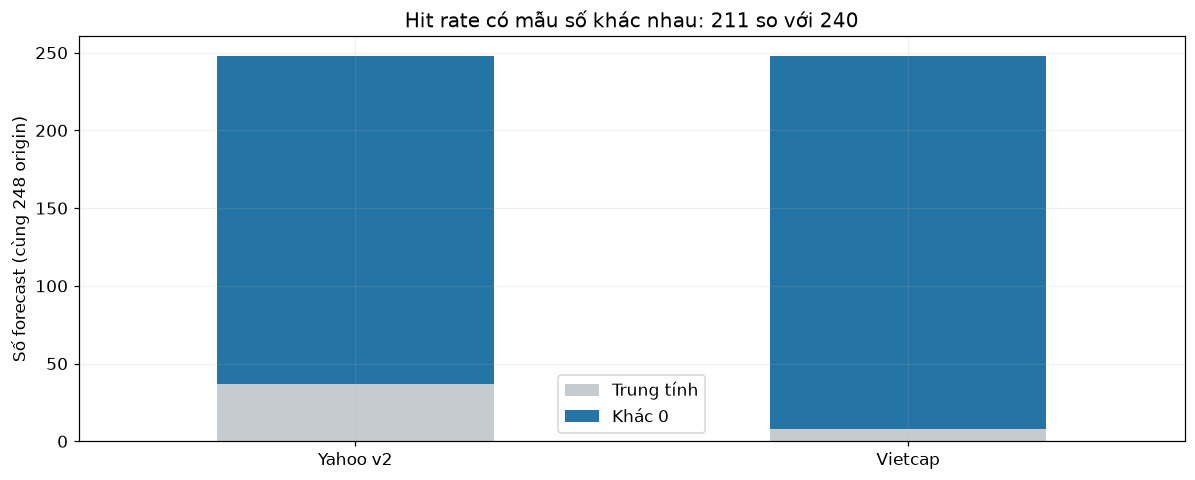

,source,feature_group,model,rmse_mean,hit_rate_mean,balanced_accuracy_mean
102,shared,baseline,Zero-Return,0.01954,NaN,NaN
104,vietcap_v3_candidate,baseline,Return Persistence,0.02719,45.83333,45.52692
106,vietcap_v3_candidate,baseline,Train Mean,0.01965,46.25000,50.00000
108,vietcap_v3_candidate,full,LSTM,0.01961,48.88889,51.17676
110,vietcap_v3_candidate,full,Ridge,0.01977,53.75000,55.71967
112,vietcap_v3_candidate,full,XGBoost,0.01957,47.91667,50.02095
114,vietcap_v3_candidate,returns,LSTM,0.01976,46.94444,50.10126
116,vietcap_v3_candidate,returns,Ridge,0.01968,45.00000,48.27153
118,vietcap_v3_candidate,returns,XGBoost,0.01958,47.77778,50.41553
120,yahoo_v2,baseline,Return Persistence,0.02780,38.75000,38.43495


Nhãn Vietcap 2025: 111 tăng, 129 giảm, 8 trung tính. Luôn đoán giảm đạt 53,75% hit rate. Cả sáu mean-seed nhóm model/features Vietcap vẫn kém Zero Return về RMSE.

In [8]:
new_pred=read(SC/'predictions.csv.gz')
ref=new_pred.query("fold == 'eval_2025' and phase == 'evaluation' and model == 'Zero-Return'")
yref=new_pred.query("fold == 'eval_2025' and phase == 'evaluation' and source == 'yahoo_v2' and feature_group == 'returns' and model == 'Ridge'")
counts=pd.DataFrame({'Nguồn nhãn':['Yahoo v2','Vietcap'], 'Trung tính':[int(yref.Target_Return_1d.eq(0).sum()),int(ref.Reference_Return.eq(0).sum())], 'Khác 0':[int(yref.Target_Return_1d.ne(0).sum()),int(ref.Reference_Return.ne(0).sum())]}).set_index('Nguồn nhãn')
assert len(ref)==248 and counts.loc['Vietcap','Trung tính']==8
ax=counts.plot.bar(stacked=True,rot=0,color=['#c6cbd0','#2474a6']); ax.set_ylabel('Số forecast (cùng 248 origin)'); ax.set_xlabel('')
ax.set_title('Hit rate có mẫu số khác nhau: 211 so với 240'); show('06_direction_denominators')
stress=source.query("fold == 'eval_2025' and phase == 'evaluation'")
display(stress[['source','feature_group','model','rmse_mean','hit_rate_mean','balanced_accuracy_mean']].round(5))
display(Markdown('Nhãn Vietcap 2025: 111 tăng, 129 giảm, 8 trung tính. Luôn đoán giảm đạt 53,75% hit rate. Cả sáu mean-seed nhóm model/features Vietcap vẫn kém Zero Return về RMSE.'))

## 6. Thí nghiệm cải thiện mới: training window
Giữ Vietcap, 6 feature lợi suất, model params/seed, validation/evaluation cohort cố định; chỉ đổi độ dài train. Window chọn theo validation, evaluation chỉ dùng chẩn đoán. Các window có cùng tập train được tái sử dụng, không đếm thành lần fit mới.

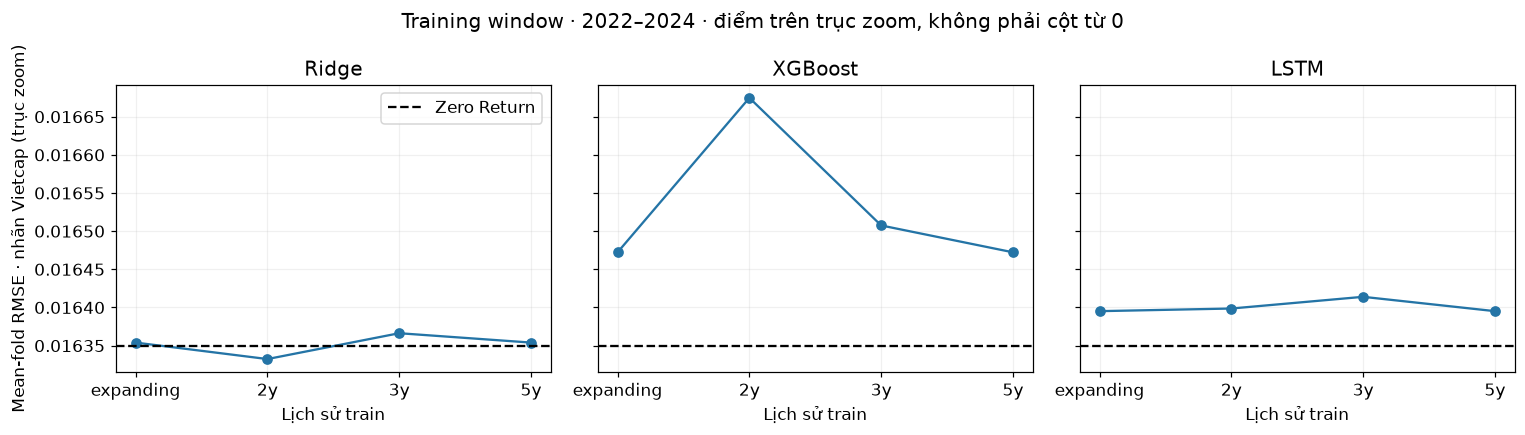

,Fold,Model,Window,Val RMSE,Eval RMSE,Control RMSE,Giảm RMSE (%)
0,eval_2022,LSTM,2y,0.018063,0.021386,0.021309,-0.361820
1,eval_2022,Return Persistence,expanding,0.024609,0.029834,0.029834,0.000000
2,eval_2022,Ridge,2y,0.018196,0.021244,0.021375,0.613015
3,eval_2022,Train Mean,2y,0.018152,0.021303,0.021278,-0.118289
4,eval_2022,XGBoost,2y,0.018557,0.021838,0.021699,-0.639954
5,eval_2022,Zero-Return,expanding,0.018313,0.021254,0.021254,0.000000
6,eval_2023,LSTM,3y,0.021187,0.012571,0.012557,-0.111562
7,eval_2023,Return Persistence,expanding,0.029834,0.017606,0.017606,0.000000
8,eval_2023,Ridge,3y,0.021367,0.012461,0.012410,-0.407760
9,eval_2023,Train Mean,expanding,0.021306,0.012292,0.012292,0.000000


Study local: `20261029T150501819490Z`. Đọc `TRAINING_HISTORY.md` và bảng selection để phân biệt kết quả chọn bằng validation với window thắng hậu nghiệm trên evaluation.

In [9]:
index=ROOT/'reports/window_comparison/studies.json'
window_studies=json.loads(index.read_text()) if index.exists() else []
complete=[s for s in window_studies if s['status']=='complete']
if complete:
    WIN=ROOT/'reports/window_comparison'/complete[-1]['study_id']
    summary=read(WIN/'summary.csv')
    fig,axes=plt.subplots(1,3,figsize=(14,4),sharey=True)
    for ax,model in zip(axes,['Ridge','XGBoost','LSTM']):
        p=summary[(summary.model==model)&(summary.phase=='evaluation')&(summary.fold!='eval_2025')]
        p=p.groupby('window').rmse_mean.mean().reindex(['expanding','2y','3y','5y'])
        ax.plot(range(len(p)),p.values,'o-',color='#2474a6'); ax.set_xticks(range(len(p)),p.index)
        zero=summary[(summary.model=='Zero-Return')&(summary.window=='expanding')&(summary.phase=='evaluation')&(summary.fold!='eval_2025')].rmse_mean.mean()
        ax.axhline(zero,color='black',linestyle='--',label='Zero Return'); ax.set_title(model); ax.set_xlabel('Lịch sử train')
    axes[0].legend(); axes[0].set_ylabel('Mean-fold RMSE · nhãn Vietcap (trục zoom)'); fig.suptitle('Training window · 2022–2024 · điểm trên trục zoom, không phải cột từ 0')
    show('07_training_window')
    selected=read(WIN/'validation_selection.csv')
    display(selected.rename(columns={'fold':'Fold','model':'Model','selected_window':'Window','validation_rmse':'Val RMSE',
        'evaluation_rmse':'Eval RMSE','expanding_evaluation_rmse':'Control RMSE','evaluation_rmse_gain_pct':'Giảm RMSE (%)'}).round(7))
    display(Markdown(f"Study local: `{WIN.name}`. Đọc `TRAINING_HISTORY.md` và bảng selection để phân biệt kết quả chọn bằng validation với window thắng hậu nghiệm trên evaluation."))
else:
    display(Markdown('Chưa có study training window hoàn tất. Chạy lại notebook sau khi kết thúc thí nghiệm để cập nhật biểu đồ.'))

### Window chọn bằng validation có giúp evaluation không?
Biểu đồ dưới chấm đúng lựa chọn từ validation, không dùng window có điểm evaluation đẹp nhất. Dương là RMSE giảm so với expanding; 2025 vẫn là chẩn đoán đã xem. Các fold chưa phải quan sát thị trường độc lập để suy ra significance.

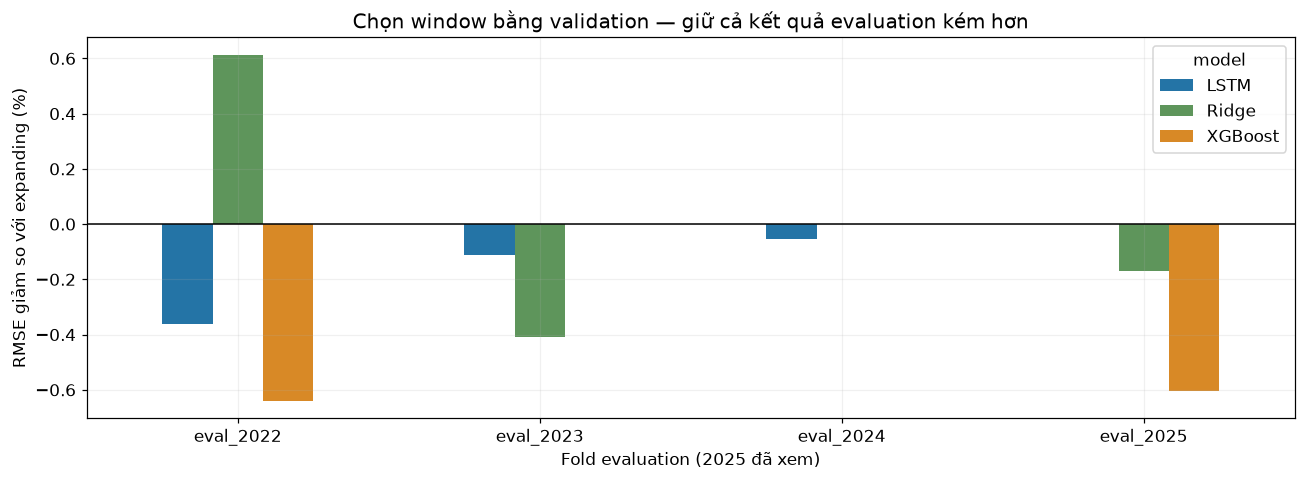

,model,selected_rmse,control_rmse,gain_pct
0,LSTM,0.016428,0.016395,-0.201618
1,Return Persistence,0.022581,0.022581,0.000000
2,Ridge,0.016327,0.016354,0.163925
3,Train Mean,0.016296,0.016292,-0.030030
4,XGBoost,0.016518,0.016472,-0.281008
5,Zero-Return,0.016350,0.016350,0.000000


**LSTM:** mean-fold 2022–2024 RMSE thay đổi -0.20% (dương = giảm).

**Ridge:** mean-fold 2022–2024 RMSE thay đổi +0.16% (dương = giảm).

**XGBoost:** mean-fold 2022–2024 RMSE thay đổi -0.28% (dương = giảm).

Ridge chọn window vẫn có RMSE cao hơn Train Mean expanding **0.22%** trên ba fold. Cải thiện so với chính model cũ chưa đủ để thay model phục vụ.

Kết quả gần baseline và không đồng nhất các fold. Chưa promote model hoặc khẳng định accuracy tương lai tăng.

In [10]:
if complete:
    chosen=selected[selected.model.isin(['Ridge','XGBoost','LSTM'])]
    gain=chosen.pivot(index='fold',columns='model',values='evaluation_rmse_gain_pct')
    ax=gain.plot.bar(figsize=(12,4.5),rot=0,color=['#2474a6','#5e955b','#d88926'])
    ax.axhline(0,color='black',lw=1); ax.set_xlabel('Fold evaluation (2025 đã xem)'); ax.set_ylabel('RMSE giảm so với expanding (%)')
    ax.set_title('Chọn window bằng validation — giữ cả kết quả evaluation kém hơn')
    show('08_window_validation_selection')
    selected_primary=read(WIN/'selected_primary_summary.csv')
    display(selected_primary.round(7))
    for r in selected_primary[selected_primary.model.isin(['Ridge','XGBoost','LSTM'])].itertuples():
        display(Markdown(f"**{r.model}:** mean-fold 2022–2024 RMSE thay đổi {r.gain_pct:+.2f}% (dương = giảm)."))
    ridge=selected_primary[selected_primary.model=='Ridge'].selected_rmse.iloc[0]
    mean_control=selected_primary[selected_primary.model=='Train Mean'].control_rmse.iloc[0]
    display(Markdown(f"Ridge chọn window vẫn có RMSE cao hơn Train Mean expanding **{100*(ridge/mean_control-1):.2f}%** trên ba fold. Cải thiện so với chính model cũ chưa đủ để thay model phục vụ."))
    display(Markdown('Kết quả gần baseline và không đồng nhất các fold. Chưa promote model hoặc khẳng định accuracy tương lai tăng.'))

## 7. Phân tích lỗi trước vòng Ridge mới
Forecast cũ đã được chọn bằng validation. Ngưỡng biến động được fit từ train từng fold; vị trí so với SMA50 là proxy, không phải nhãn thị trường chính thức. Đây là chẩn đoán mô tả, không dùng chọn hyperparameter theo evaluation.

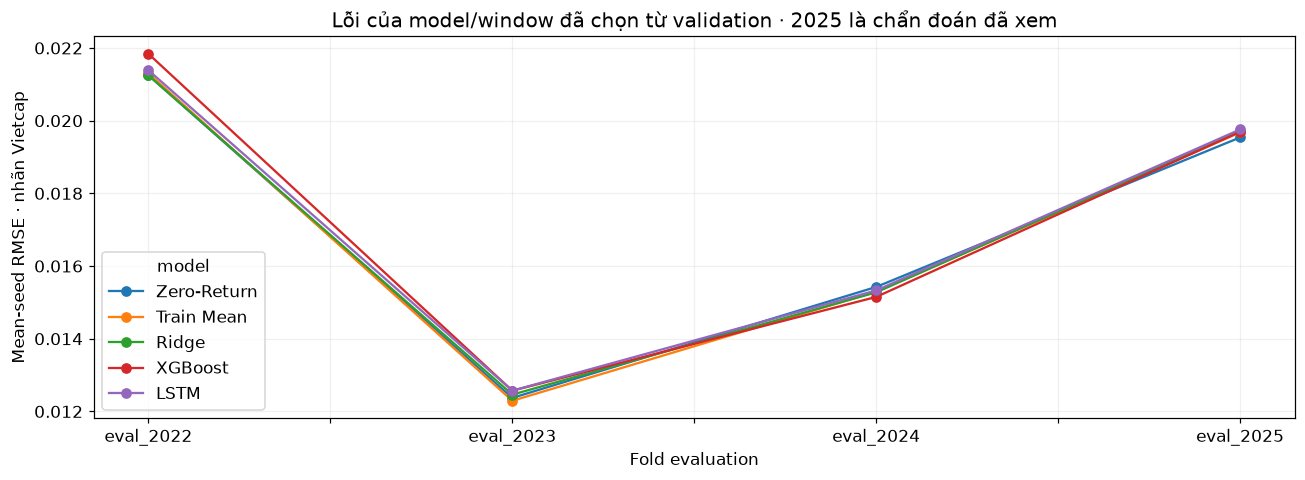

model,Zero-Return,Train Mean,Ridge,XGBoost,LSTM
fold,,,,,
eval_2022,0.021254,0.021303,0.021244,0.021838,0.021386
eval_2023,0.012371,0.012292,0.012461,0.012568,0.012571
eval_2024,0.015424,0.015294,0.015277,0.015149,0.015328
eval_2025,0.019538,0.019674,0.019716,0.019694,0.019757


In [11]:
refinement_index=ROOT/'reports/ridge_refinement/studies.json'
refinements=json.loads(refinement_index.read_text()) if refinement_index.exists() else []
completed_refinements=[s for s in refinements if s['status']=='complete']
if completed_refinements:
    REFINE=ROOT/'reports/ridge_refinement'/completed_refinements[-1]['study_id']
    errors=read(REFINE/'error_by_fold_seed.csv')
    annual=errors.groupby(['fold','model']).rmse.mean().unstack()[['Zero-Return','Train Mean','Ridge','XGBoost','LSTM']]
    ax=annual.plot(marker='o',figsize=(12,4.5));ax.set_ylabel('Mean-seed RMSE · nhãn Vietcap');ax.set_xlabel('Fold evaluation')
    ax.set_title('Lỗi của model/window đã chọn từ validation · 2025 là chẩn đoán đã xem')
    show('09_errors_by_year')
    display(annual.round(7))
else:
    display(Markdown('Chưa có study phân tích lỗi/Ridge refinement hoàn tất.'))

### Nhóm nào khó so với Zero Return?
Skill dương tốt hơn Zero Return. N là origin duy nhất; tỷ trọng loss đã bình quân theo seed tại mỗi origin để tránh đếm một ngày ba lần. Mức RMSE tuyệt đối cao có thể phản ánh thị trường biến động, nên cần xem cả skill tương đối.

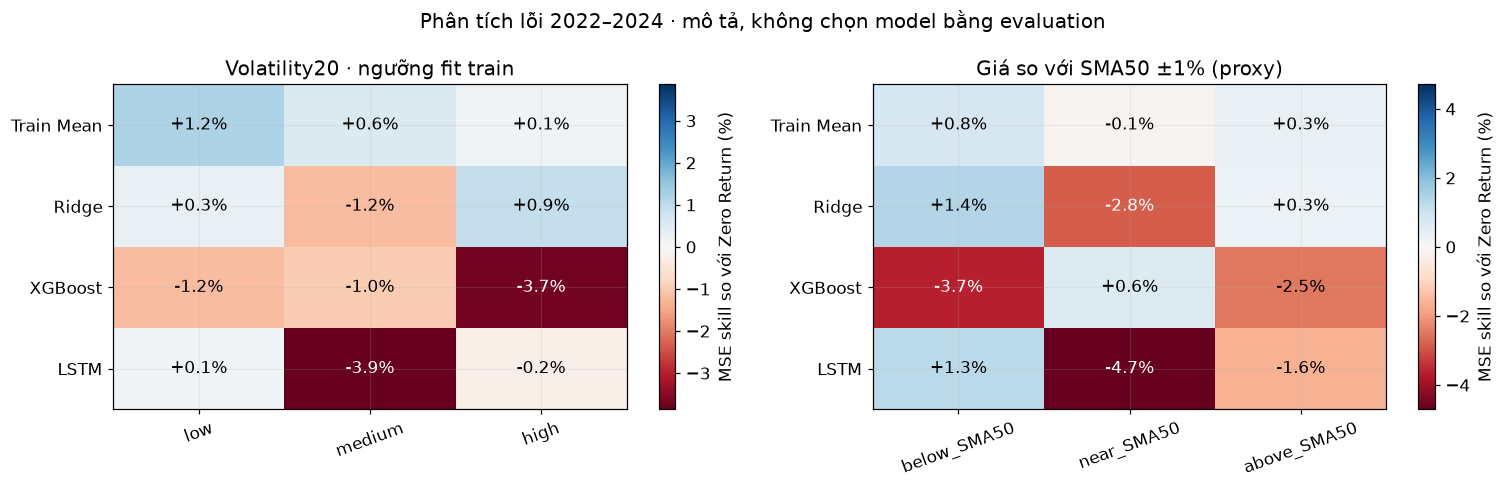

,segment,unique_origins,mean_seed_rmse,mean_seed_mse_skill_vs_zero,squared_loss_share_pct
6,high,243,0.02160,0.00913,55.63890
7,low,308,0.01233,0.00274,22.98676
8,medium,178,0.01564,-0.01188,21.37434


Khoảng 33% origin biến động cao chiếm 56% squared loss của Ridge. Ridge vẫn nhỉnh hơn Zero ở nhóm này; nhóm biến động trung bình có skill âm. Không loại các ngày khó để làm điểm đẹp.

In [12]:
if completed_refinements:
    segments=read(REFINE/'error_segments.csv')
    fig,axes=plt.subplots(1,2,figsize=(14,4.5))
    for ax,dimension,order,title in [(axes[0],'vol_regime',['low','medium','high'],'Volatility20 · ngưỡng fit train'),
                                    (axes[1],'trend_proxy',['below_SMA50','near_SMA50','above_SMA50'],'Giá so với SMA50 ±1% (proxy)')]:
        p=segments[(segments.scope=='primary')&(segments.segmentation==dimension)]
        grid=p.pivot(index='model',columns='segment',values='mean_seed_mse_skill_vs_zero').reindex(index=['Train Mean','Ridge','XGBoost','LSTM'],columns=order)*100
        limit=max(1.,float(np.nanmax(abs(grid.to_numpy()))))
        im=ax.imshow(grid,aspect='auto',cmap='RdBu',vmin=-limit,vmax=limit)
        ax.set_xticks(range(3),grid.columns,rotation=20);ax.set_yticks(range(4),grid.index);ax.set_title(title)
        for i in range(4):
            for j in range(3):ax.text(j,i,f'{grid.iloc[i,j]:+.1f}%',ha='center',va='center',color='white' if abs(grid.iloc[i,j])>.6*limit else 'black')
        fig.colorbar(im,ax=ax,label='MSE skill so với Zero Return (%)')
    fig.suptitle('Phân tích lỗi 2022–2024 · mô tả, không chọn model bằng evaluation');show('10_error_regimes')
    display(segments[(segments.scope=='primary')&(segments.segmentation=='vol_regime')&(segments.model=='Ridge')][['segment','unique_origins','mean_seed_rmse','mean_seed_mse_skill_vs_zero','squared_loss_share_pct']].round(5))
    display(Markdown('Khoảng 33% origin biến động cao chiếm 56% squared loss của Ridge. Ridge vẫn nhỉnh hơn Zero ở nhóm này; nhóm biến động trung bình có skill âm. Không loại các ngày khó để làm điểm đẹp.'))

## 8. Ridge: regularization và training window
Grid alpha 0.1/1/10/100/1000 được khóa trước fit. Alpha-only giữ window cũ; joint chọn alpha và window bằng validation. Alpha10 phải tái lập đúng control. Ridge xác định nên không tạo seed SD hoặc confidence interval giả. Đây là đợt hồi cứu thích nghi sau các nghiên cứu cũ, chưa phải đánh giá tương lai.

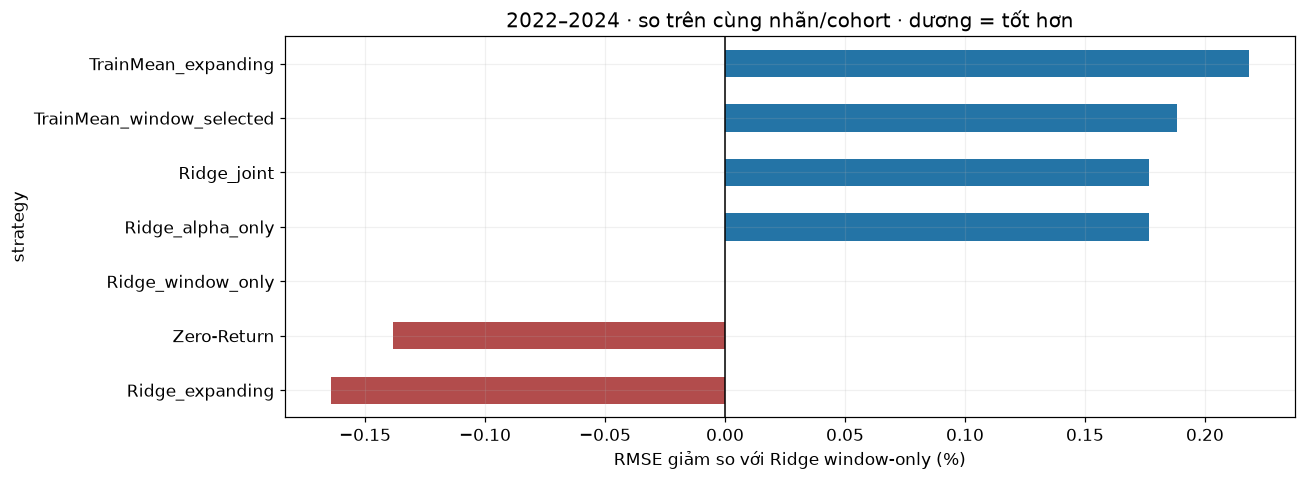

,strategy,mean_fold_rmse,mean_fold_mae,worst_fold_rmse,positive_skill_folds,rmse_gain_vs_previous_ridge_pct
0,Ridge_alpha_only,0.016298,0.011439,0.021277,2,0.176478
1,Ridge_expanding,0.016354,0.011433,0.021375,1,-0.164194
2,Ridge_joint,0.016298,0.011439,0.021277,2,0.176478
3,Ridge_window_only,0.016327,0.011442,0.021244,2,0.000000
4,TrainMean_expanding,0.016292,0.011453,0.021278,2,0.218267
5,TrainMean_window_selected,0.016296,0.011459,0.021303,2,0.188303
6,Zero-Return,0.016350,0.011455,0.021254,0,-0.138473


,fold,window,alpha,grid_boundary,validation_rmse
3,eval_2022,2y,1000.0,True,0.018146
10,eval_2023,3y,1000.0,True,0.021297
17,eval_2024,expanding,1000.0,True,0.012345
24,eval_2025,3y,100.0,False,0.015229


Ridge joint giảm RMSE **0.18%** so với Ridge window-only, nhưng còn cao hơn Train Mean expanding **0.04%**. Worst-fold RMSE phải được đọc cùng trung bình; chưa promote model.

Joint và alpha-only chọn cùng cấu hình ở cả bốn fold. Alpha nằm ở biên trên grid trong ba fold chính; dự báo co về gần trung bình hơn, chưa chứng minh thêm tín hiệu dự báo.

In [13]:
if completed_refinements:
    refined=read(REFINE/'primary_summary.csv')
    p=refined.sort_values('rmse_gain_vs_previous_ridge_pct')
    ax=p.set_index('strategy').rmse_gain_vs_previous_ridge_pct.plot.barh(figsize=(12,4.5),color=['#b24c4c' if x<0 else '#2474a6' for x in p.rmse_gain_vs_previous_ridge_pct])
    ax.axvline(0,color='black',lw=1);ax.set_xlabel('RMSE giảm so với Ridge window-only (%)');ax.set_title('2022–2024 · so trên cùng nhãn/cohort · dương = tốt hơn')
    show('11_ridge_refinement')
    display(refined.round(7))
    choices=read(REFINE/'validation_selection.csv')
    display(choices[choices.strategy=='Ridge_joint'][['fold','window','alpha','grid_boundary','rmse']].rename(columns={'rmse':'validation_rmse'}).round(7))
    r=refined[refined.strategy=='Ridge_joint'].iloc[0];m=refined[refined.strategy=='TrainMean_expanding'].iloc[0]
    display(Markdown(f"Ridge joint giảm RMSE **{r.rmse_gain_vs_previous_ridge_pct:.2f}%** so với Ridge window-only, nhưng còn cao hơn Train Mean expanding **{100*(r.mean_fold_rmse/m.mean_fold_rmse-1):.2f}%**. Worst-fold RMSE phải được đọc cùng trung bình; chưa promote model."))
    display(Markdown('Joint và alpha-only chọn cùng cấu hình ở cả bốn fold. Alpha nằm ở biên trên grid trong ba fold chính; dự báo co về gần trung bình hơn, chưa chứng minh thêm tín hiệu dự báo.'))

### Đối chiếu validation grid
Mỗi panel có colorbar RMSE riêng; chỉ dùng validation chọn cấu hình. Nhãn alpha lớn hơn thường co hệ số mạnh hơn, nhưng hiệu lực còn phụ thuộc N train (alpha/N được lưu trong manifest). Không so màu giữa các fold như thể cùng thang đo.

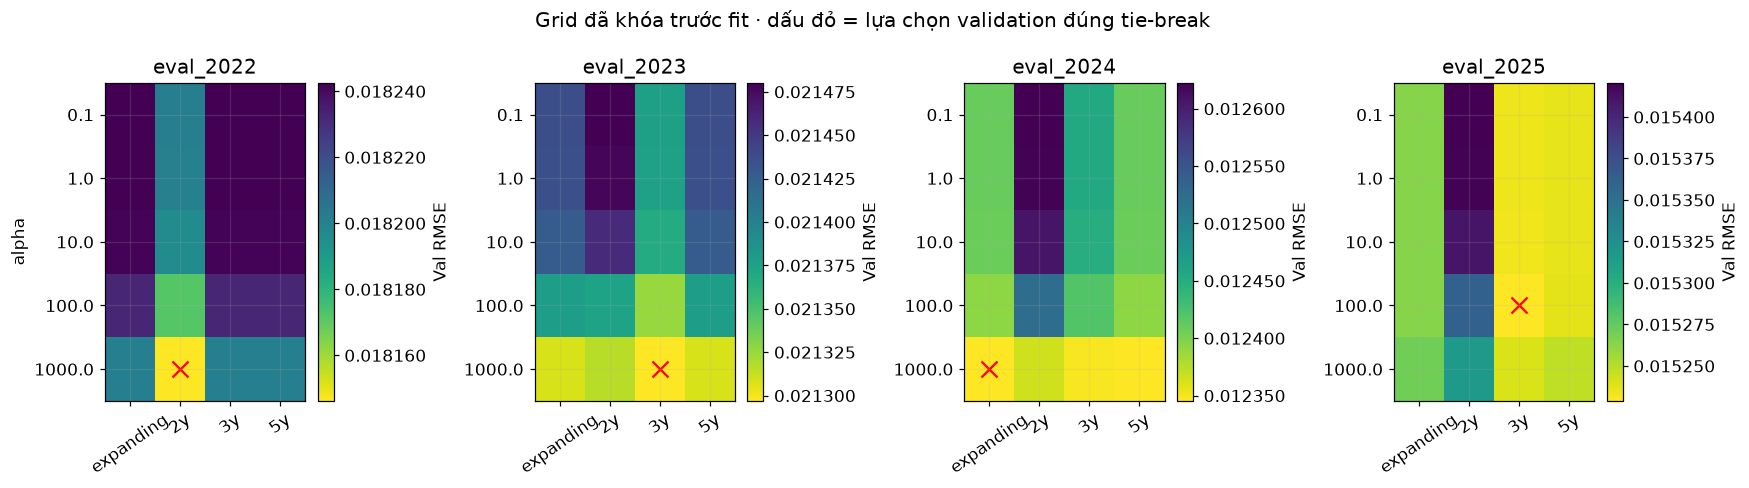

Nguồn số liệu: `reports\ridge_refinement\20261030T011109863274Z`. Lượt dừng do lỗi export được giữ riêng trong studies.json, không trộn vào kết quả so sánh hoàn tất.

In [14]:
if completed_refinements:
    grid_scores=read(REFINE/'metrics.csv')
    fig,axes=plt.subplots(1,4,figsize=(16,4.5))
    for ax,(fold,p) in zip(axes,grid_scores[grid_scores.phase=='validation'].groupby('fold')):
        grid=p.pivot(index='alpha',columns='window',values='rmse').reindex(index=[.1,1.,10.,100.,1000.],columns=['expanding','2y','3y','5y'])
        im=ax.imshow(grid,aspect='auto',cmap='viridis_r');ax.set_xticks(range(4),grid.columns,rotation=35);ax.set_yticks(range(5),grid.index);ax.set_title(fold)
        chosen=choices[(choices.fold==fold)&(choices.strategy=='Ridge_joint')].iloc[0]
        ax.scatter(grid.columns.get_loc(chosen.window),grid.index.get_loc(chosen.alpha),marker='x',color='red',s=110)
        fig.colorbar(im,ax=ax,label='Val RMSE',format='%.6f')
    axes[0].set_ylabel('alpha')
    fig.suptitle('Grid đã khóa trước fit · dấu đỏ = lựa chọn validation đúng tie-break');show('12_ridge_validation_grid')
    display(Markdown(f"Nguồn số liệu: `{REFINE.relative_to(ROOT)}`. Lượt dừng do lỗi export được giữ riêng trong studies.json, không trộn vào kết quả so sánh hoàn tất."))

## 9. Model đóng băng dự báo các ngày 2026 ra sao?
Weights/scaler/baseline được khóa trước request 2026; không refit/chọn theo 2026. Dữ liệu đến hết 29/10/2026. Đây là temporal evaluation được mở mới trong workflow nhưng **hồi cứu**, không phải forecast đã ghi live trước thị trường. Khoảng 2026 này nay đã được xem. Mỗi forecast chỉ là một quan sát kế tiếp sau origin đã biết OHLCV, không dự báo tự động cả đường giá năm.

Nguồn và cutoff train khác nhau giữa serving/research nên so chéo family không cô lập riêng thuật toán. Giá MAE dùng cùng anchor Vietcap đã điều chỉnh; MAPE không phải xác suất đúng.

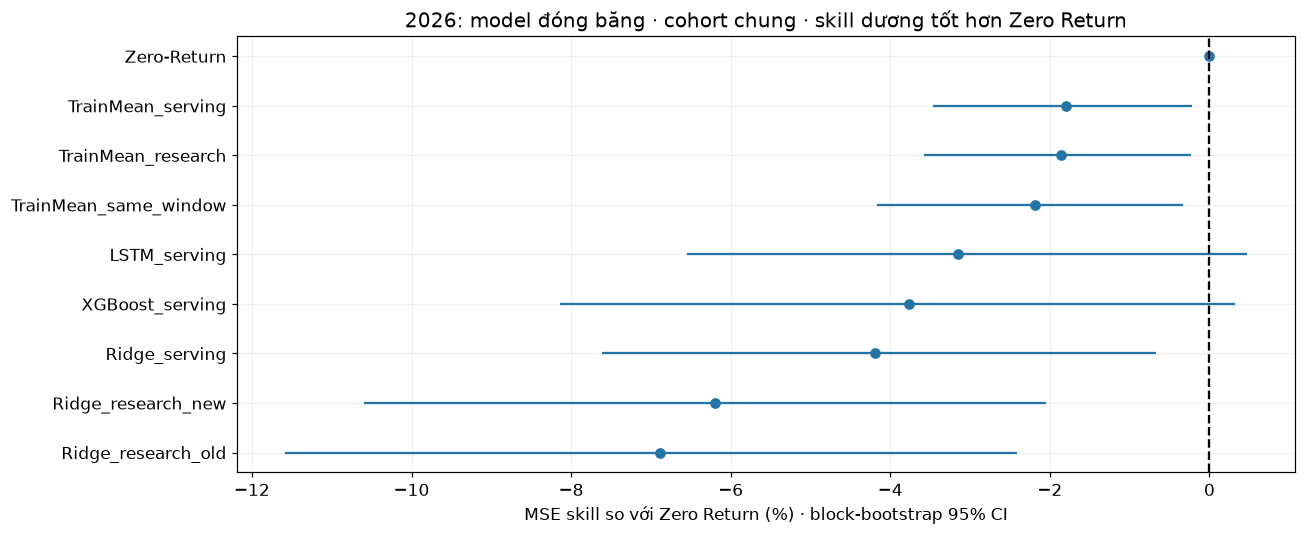

,model,n,rmse,price_mae_adjusted_vnd,price_mape_pct,hit_rate_pct,balanced_accuracy_pct
7,Zero-Return,200,0.02011,1082.06035,1.53993,NaN,NaN
9,TrainMean_serving,200,0.02029,1099.94764,1.56723,40.00000,50.00000
11,TrainMean_research,200,0.02030,1100.42421,1.56796,40.00000,50.00000
13,TrainMean_same_window,200,0.02033,1103.10464,1.57205,40.00000,50.00000
0,LSTM_serving,200,0.02043,1092.45646,1.55544,51.28205,54.27350
1,XGBoost_serving,200,0.02049,1106.20859,1.57605,43.58974,47.64957
2,Ridge_serving,200,0.02053,1090.73265,1.55600,46.15385,50.42735
3,Ridge_research_new,200,0.02073,1116.12872,1.59556,42.56410,49.78632
5,Ridge_research_old,200,0.02079,1119.52651,1.60097,42.05128,48.71795


CI dùng block 10 origin/2.000 resamples, seed cố định. Đây là độ bất định mô tả, không bảo đảm thị trường tương lai. LSTM CI chứa 0; Ridge research có point estimate kém Zero Return.

In [15]:
eval_index=ROOT/'reports/evaluation_2026/studies.json'
evaluations=json.loads(eval_index.read_text()) if eval_index.exists() else []
completed_evaluations=[s for s in evaluations if s['status']=='complete']
if completed_evaluations:
    EVAL=ROOT/'reports/evaluation_2026'/completed_evaluations[-1]['study_id']
    em=read(EVAL/'metrics.csv');common_metrics=em[em.cohort=='common'].sort_values('rmse')
    p=common_metrics.sort_values('mse_skill_vs_zero')
    fig,ax=plt.subplots(figsize=(12,5))
    ax.hlines(range(len(p)),100*p.mse_skill_ci_low,100*p.mse_skill_ci_high,color='#2474a6')
    ax.scatter(100*p.mse_skill_vs_zero,range(len(p)),color='#2474a6');ax.axvline(0,color='black',ls='--')
    ax.set_yticks(range(len(p)),p.model);ax.set_xlabel('MSE skill so với Zero Return (%) · block-bootstrap 95% CI')
    ax.set_title('2026: model đóng băng · cohort chung · skill dương tốt hơn Zero Return')
    show('13_2026_skill_intervals')
    display(common_metrics[['model','n','rmse','price_mae_adjusted_vnd','price_mape_pct','hit_rate_pct','balanced_accuracy_pct']].round(5))
    display(Markdown('CI dùng block 10 origin/2.000 resamples, seed cố định. Đây là độ bất định mô tả, không bảo đảm thị trường tương lai. LSTM CI chứa 0; Ridge research có point estimate kém Zero Return.'))
else:
    display(Markdown('Chưa có lượt đánh giá 2026 hoàn tất. Không tự tải 2026 khi chạy notebook.'))

### Độ ổn định theo tháng và thiên lệch dự báo
Không chốt chất lượng bằng một hit rate gộp. Tháng có 15–23 mẫu khá ít; độ biến động/nhãn thay đổi làm RMSE thay đổi. Model dự báo bằng dữ liệu đã quan sát đến origin, không dùng nhãn tiếp theo làm input.

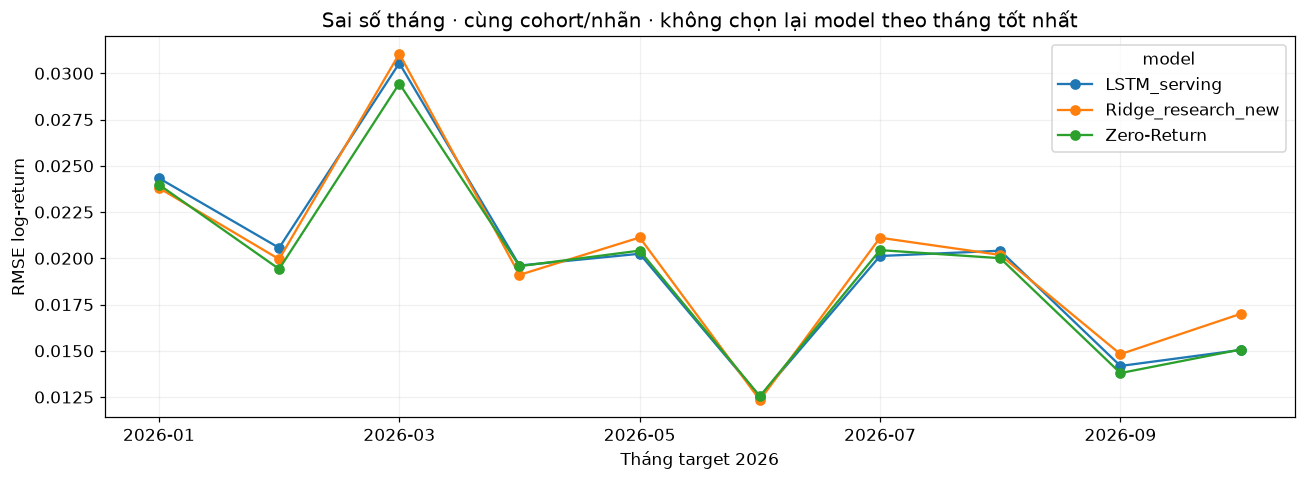

,target_month,model,n,rmse,mse_skill_vs_zero
0,2026-01,LSTM_serving,19,0.024331,-0.029519
1,2026-02,LSTM_serving,15,0.020562,-0.121357
2,2026-03,LSTM_serving,22,0.030544,-0.076116
3,2026-04,LSTM_serving,20,0.019606,-0.003545
4,2026-05,LSTM_serving,20,0.020243,0.016550
5,2026-06,LSTM_serving,22,0.012525,0.002679
6,2026-07,LSTM_serving,23,0.020122,0.030869
7,2026-08,LSTM_serving,20,0.020408,-0.040797
8,2026-09,LSTM_serving,18,0.014179,-0.056658
9,2026-10,LSTM_serving,21,0.015042,0.003287


In [16]:
if completed_evaluations:
    months=read(EVAL/'monthly_metrics.csv')
    p=months[(months.cohort=='common')&months.model.isin(['LSTM_serving','Ridge_research_new','Zero-Return'])]
    grid=p.pivot(index='target_month',columns='model',values='rmse')
    ax=grid.plot(marker='o',figsize=(12,4.5));ax.set_ylabel('RMSE log-return');ax.set_xlabel('Tháng target 2026')
    ax.set_title('Sai số tháng · cùng cohort/nhãn · không chọn lại model theo tháng tốt nhất')
    show('14_2026_monthly_errors')
    display(p[['target_month','model','n','rmse','mse_skill_vs_zero']].round(6))

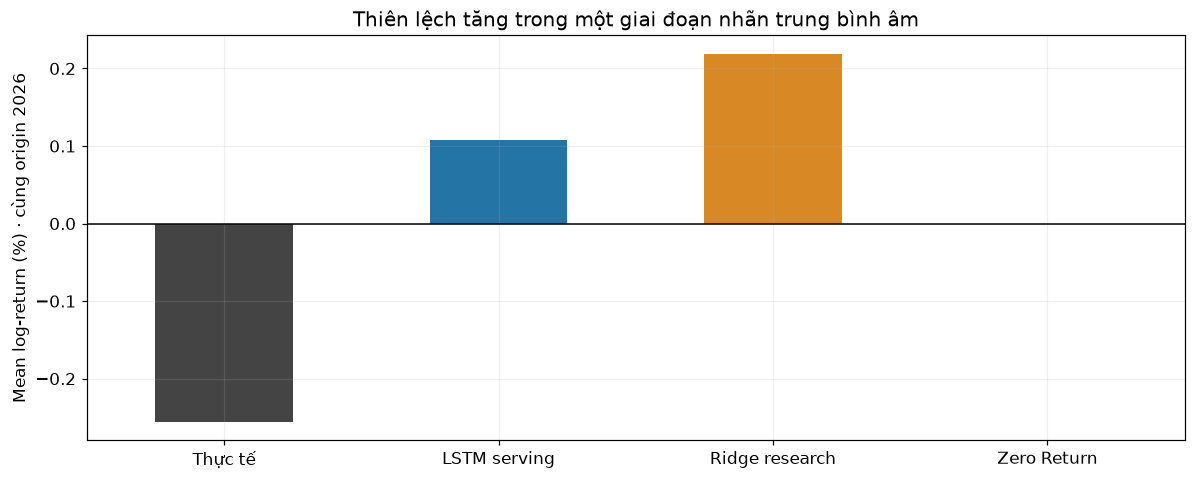

,predicted_up_pct_all_origins,actual_up_pct_nonzero,up_recall_pct,down_recall_pct
model,,,,
LSTM_serving,63.0,40.0,69.23,39.32
Ridge_research_new,86.5,40.0,85.90,13.68
Ridge_research_old,84.0,40.0,82.05,15.38
Ridge_serving,70.5,40.0,71.79,29.06
TrainMean_research,100.0,40.0,100.00,0.00
TrainMean_same_window,100.0,40.0,100.00,0.00
TrainMean_serving,100.0,40.0,100.00,0.00
XGBoost_serving,70.5,40.0,67.95,27.35
Zero-Return,0.0,40.0,0.00,0.00


Luôn đoán giảm đạt 60% hit trên 195 nhãn khác 0; balanced accuracy 50%. LSTM hit 51,28%, balanced 54,27%; hai metric trả lời câu hỏi khác nhau. MAPE 1,56% không có nghĩa 98,44% forecast đúng. Chưa có lợi thế hồi quy vượt Zero Return trong cohort này.

In [17]:
if completed_evaluations:
    bias=read(EVAL/'bias_diagnostics.csv').set_index('model')
    values=pd.Series({'Thực tế':bias.loc['LSTM_serving','actual_mean_log_return'],
                      'LSTM serving':bias.loc['LSTM_serving','predicted_mean_log_return'],
                      'Ridge research':bias.loc['Ridge_research_new','predicted_mean_log_return'],
                      'Zero Return':0.})*100
    ax=values.plot.bar(rot=0,color=['#444444','#2474a6','#d88926','#9ea4a9']);ax.axhline(0,color='black',lw=1)
    ax.set_ylabel('Mean log-return (%) · cùng origin 2026');ax.set_title('Thiên lệch tăng trong một giai đoạn nhãn trung bình âm')
    show('15_2026_bias')
    display(bias[['predicted_up_pct_all_origins','actual_up_pct_nonzero','up_recall_pct','down_recall_pct']].round(2))
    display(Markdown('Luôn đoán giảm đạt 60% hit trên 195 nhãn khác 0; balanced accuracy 50%. LSTM hit 51,28%, balanced 54,27%; hai metric trả lời câu hỏi khác nhau. MAPE 1,56% không có nghĩa 98,44% forecast đúng. Chưa có lợi thế hồi quy vượt Zero Return trong cohort này.'))

## 10. Train gần hiện tại hơn và hiệu chỉnh bias
Giữ 6 return features, alpha100, window3y. So artifact cũ, rebuild đúng 693 ngày từ snapshot mới, mở coverage native cùng cutoff, refit đến cuối 2025 và mô phỏng refit đầu tháng 2026. Chỉ dùng target ≤ cutoff. Phần 2026 đã xem nên **không phải holdout độc lập mới**; current adjusted history chưa point-in-time certified. Không promote theo thứ hạng ở đây.

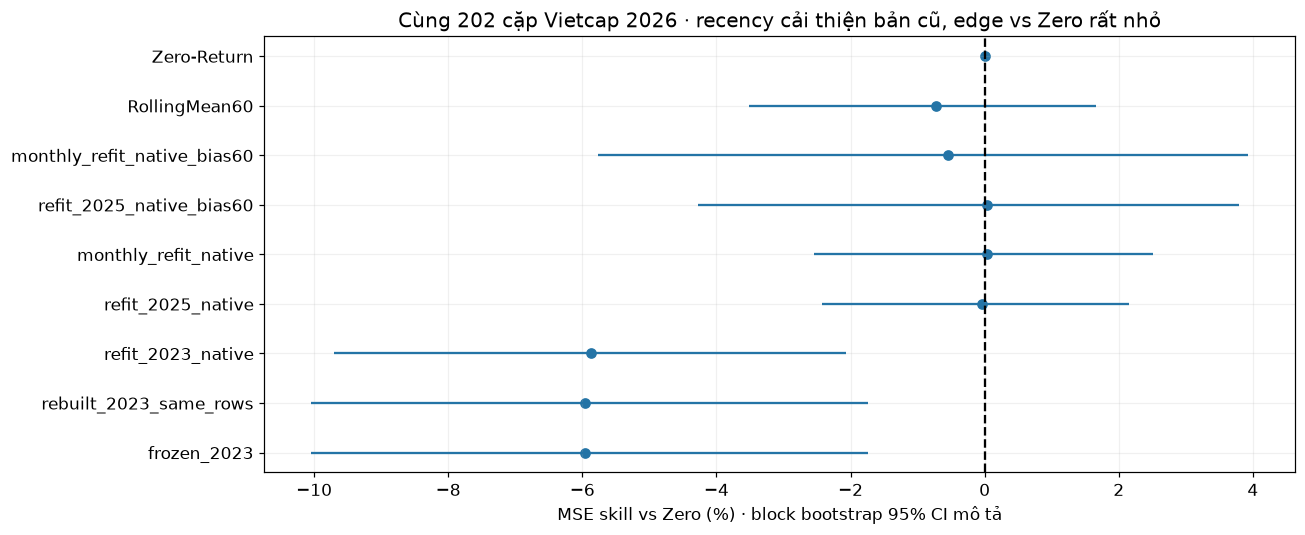

,n,rmse,price_mae_adjusted_vnd,hit_rate_pct,balanced_accuracy_pct,mse_skill_vs_zero
strategy,,,,,,
frozen_2023,202,0.020706,1114.182188,43.147208,49.962607,-0.059532
rebuilt_2023_same_rows,202,0.020706,1114.182188,43.147208,49.962607,-0.059532
refit_2023_native,202,0.020697,1114.204951,43.147208,50.357906,-0.058666
refit_2025_native,202,0.020119,1080.944044,50.761421,54.198718,-0.000332
monthly_refit_native,202,0.020112,1074.001675,52.791878,54.524573,0.000336
refit_2025_native_bias60,202,0.020112,1064.115342,60.913706,56.618590,0.000408
monthly_refit_native_bias60,202,0.020170,1063.569306,57.868020,54.252137,-0.005446
RollingMean60,202,0.020189,1075.321842,52.791878,47.013889,-0.007298
Zero-Return,202,0.020116,1081.698020,NaN,NaN,0.000000


Refit đến cuối 2025 giảm RMSE **2.83%** so với bản cũ. Rebuild đúng ngày tái lập điểm cũ: revision không giải thích lợi ích ở lượt này. Bản static+bias có MSE skill **+0.041%**, CI chứa 0; chưa chứng minh lợi thế vs Zero. Đây là bảng chẩn đoán, không chọn winner để deploy.

In [18]:
recency_index=ROOT/'reports/recency_bias/studies.json'
recency_studies=json.loads(recency_index.read_text()) if recency_index.exists() else []
completed_recency=[s for s in recency_studies if s['status']=='complete']
if completed_recency:
    RECENCY=ROOT/'reports/recency_bias'/completed_recency[-1]['study_id']
    rm=read(RECENCY/'primary_summary.csv').set_index('strategy')
    order=['frozen_2023','rebuilt_2023_same_rows','refit_2023_native','refit_2025_native','monthly_refit_native',
           'refit_2025_native_bias60','monthly_refit_native_bias60','RollingMean60','Zero-Return']
    p=rm.loc[order];ci=read(RECENCY/'uncertainty_descriptive.csv').set_index('strategy').loc[order]
    fig,ax=plt.subplots(figsize=(12,5))
    ax.hlines(range(len(p)),100*ci.mse_skill_ci_low,100*ci.mse_skill_ci_high,color='#2474a6')
    ax.scatter(100*p.mse_skill_vs_zero,range(len(p)),color='#2474a6');ax.axvline(0,color='black',ls='--')
    ax.set_yticks(range(len(p)),p.index);ax.set_xlabel('MSE skill vs Zero (%) · block bootstrap 95% CI mô tả')
    ax.set_title('Cùng 202 cặp Vietcap 2026 · recency cải thiện bản cũ, edge vs Zero rất nhỏ')
    show('16_recency_bias_skill')
    display(p[['n','rmse','price_mae_adjusted_vnd','hit_rate_pct','balanced_accuracy_pct','mse_skill_vs_zero']].round(6))
    old=rm.loc['frozen_2023'];fresh=rm.loc['refit_2025_native'];biased=rm.loc['refit_2025_native_bias60']
    display(Markdown(f"Refit đến cuối 2025 giảm RMSE **{100*(1-fresh.rmse/old.rmse):.2f}%** so với bản cũ. Rebuild đúng ngày tái lập điểm cũ: revision không giải thích lợi ích ở lượt này. Bản static+bias có MSE skill **{100*biased.mse_skill_vs_zero:+.3f}%**, CI chứa 0; chưa chứng minh lợi thế vs Zero. Đây là bảng chẩn đoán, không chọn winner để deploy."))
else:
    display(Markdown('Chưa có đối chứng recency/bias hoàn tất.'))

### Bias có giúp ổn định mọi tháng không?
Bias dùng tối đa 60 residual đã chín, đủ 20 mới hiệu chỉnh; 20 origin đầu giữ raw. Đường theo tháng là chẩn đoán cùng origin/nhãn; không chọn tháng tốt để báo cáo. Bảng dưới so raw/bias trên cùng 182 ngày đủ warm-up.

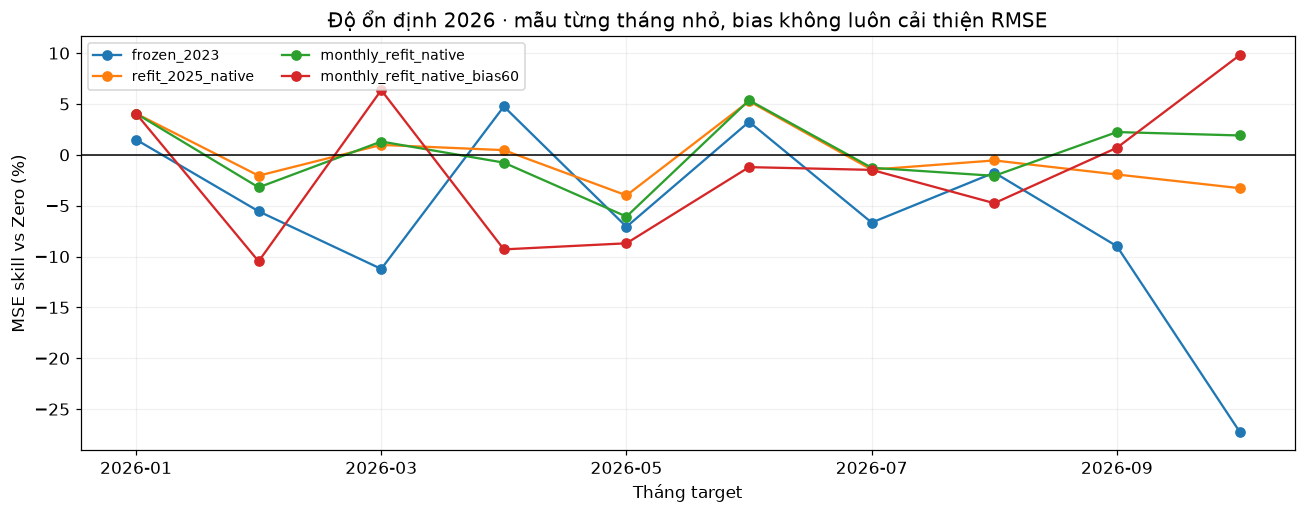

,comparison,strategy,n,rmse,hit_rate_pct,balanced_accuracy_pct
0,frozen_2023_bias60,frozen_2023_bias60,182,0.020155,51.977401,47.930574
1,frozen_2023_bias60,frozen_2023,182,0.020414,41.807910,49.893191
4,monthly_refit_native_bias60,monthly_refit_native_bias60,182,0.019848,57.627119,52.850467
5,monthly_refit_native_bias60,monthly_refit_native,182,0.019782,51.977401,53.858478
8,refit_2025_native_bias60,refit_2025_native_bias60,182,0.019782,61.016949,55.407210
9,refit_2025_native_bias60,refit_2025_native,182,0.019790,49.717514,53.718291


Bias giảm mean error nhưng bản monthly+bias có RMSE xấu hơn monthly raw, cả trên cùng ngày bias-ready. Hit cao còn phụ thuộc tỷ lệ tăng/giảm: luôn đoán giảm đạt 59,39% hit trên 197 nhãn khác 0; balanced accuracy 50%.

In [19]:
if completed_recency:
    monthly=read(RECENCY/'monthly_metrics.csv')
    order=['frozen_2023','refit_2025_native','monthly_refit_native','monthly_refit_native_bias60']
    grid=monthly[monthly.strategy.isin(order)].pivot(index='target_month',columns='strategy',values='mse_skill_vs_zero').reindex(columns=order)*100
    ax=grid.plot(marker='o',figsize=(12,4.8));ax.axhline(0,color='black',lw=1)
    ax.set_ylabel('MSE skill vs Zero (%)');ax.set_xlabel('Tháng target');ax.set_title('Độ ổn định 2026 · mẫu từng tháng nhỏ, bias không luôn cải thiện RMSE')
    ax.legend(fontsize=9,ncol=2);show('17_recency_monthly_skill')
    matched=read(RECENCY/'matched_warmup_comparison.csv')
    display(matched[matched.scope=='bias_ready'][['comparison','strategy','n','rmse','hit_rate_pct','balanced_accuracy_pct']].round(6))
    display(Markdown('Bias giảm mean error nhưng bản monthly+bias có RMSE xấu hơn monthly raw, cả trên cùng ngày bias-ready. Hit cao còn phụ thuộc tỷ lệ tăng/giảm: luôn đoán giảm đạt 59,39% hit trên 197 nhãn khác 0; balanced accuracy 50%.'))

### Khoảng dự báo và bằng chứng tương lai
Khoảng danh nghĩa 80% dùng quantile 10–90% của 60 lỗi calibrated trước đó; cần đủ 60 nhãn, không dựng khoảng cho warm-up. Đây là empirical residual interval, không bảo đảm coverage. Biểu đồ dùng forecast **mô phỏng hồi cứu**; không phải forecast mới đã ghi live. Bundle shadow riêng refit đến 29/10 và giữ calibration cố định tới khi chủ động rebuild.

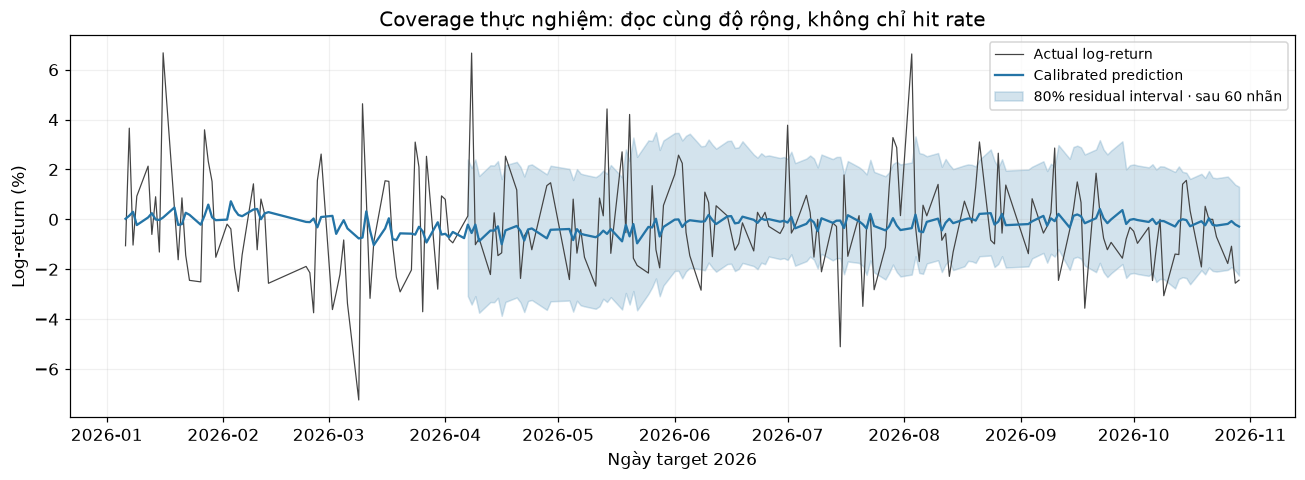

,interval_n,interval_coverage_pct,mean_interval_width_log_return
strategy,,,
frozen_2023_bias60,142,80.98592,0.04518
refit_2025_native_bias60,142,82.39437,0.04602
monthly_refit_native_bias60,142,83.09859,0.04613


Sổ shadow local: **1 forecast, 0 outcome, 0 outcome full-session**. Chưa có nhãn thì chưa kết luận forward. Chỉ phát trước ngày target mới được chấm full-session. Forecast sáng cùng ngày target bị loại khỏi nhóm này. Hướng dẫn: `ARCHITECTURE.md#forward-ledger`; chi tiết: `reports\recency_bias\20261030T022440928507Z/metrics.csv`.

In [20]:
if completed_recency:
    rp=read(RECENCY/'predictions.csv.gz')
    g=rp[(rp.cohort=='vci_full')&(rp.strategy=='monthly_refit_native_bias60')].copy()
    dates=pd.to_datetime(g.Target_Date_1d);valid=g.lower_log_return.notna()
    fig,ax=plt.subplots(figsize=(12,4.5))
    ax.plot(dates,100*g.Reference_Return,lw=.8,color='#444',label='Actual log-return')
    ax.plot(dates,100*g.predicted_log_return,color='#2474a6',label='Calibrated prediction')
    ax.fill_between(dates[valid],100*g.loc[valid,'lower_log_return'],100*g.loc[valid,'upper_log_return'],alpha=.2,color='#2474a6',label='80% residual interval · sau 60 nhãn')
    ax.set_ylabel('Log-return (%)');ax.set_xlabel('Ngày target 2026');ax.set_title('Coverage thực nghiệm: đọc cùng độ rộng, không chỉ hit rate')
    ax.legend(fontsize=9);show('18_recency_empirical_interval')
    display(rm[rm.interval_n.gt(0)][['interval_n','interval_coverage_pct','mean_interval_width_log_return']].round(5))
    ledger=ROOT/'reports/forward_shadow/forecasts.jsonl'
    events=[json.loads(line) for line in ledger.read_text(encoding='utf-8').splitlines()] if ledger.exists() else []
    forecasts=[e for e in events if e['kind']=='forecast'];outcomes=[e for e in events if e['kind']=='outcome']
    eligible=[e for e in outcomes if e['full_session_eligible']]
    display(Markdown(f"Sổ shadow local: **{len(forecasts)} forecast, {len(outcomes)} outcome, {len(eligible)} outcome full-session**. Chưa có nhãn thì chưa kết luận forward. Chỉ phát trước ngày target mới được chấm full-session. Forecast sáng cùng ngày target bị loại khỏi nhóm này. Hướng dẫn: `ARCHITECTURE.md#forward-ledger`; chi tiết: `{RECENCY.relative_to(ROOT)}/metrics.csv`."))

## 11. Phân loại tăng/giảm và vùng chưa đủ tín hiệu
Phần này gom kết quả notebook phân loại cũ. Chỉ đọc study đã hoàn tất, không fit/calibrate lại.
Train đến tháng 6 năm trước, calibration Q3, validation chọn margin Q4, rồi evaluation năm sau.
Ridge_shared dùng cùng dòng train với classifier; Ridge_recent có thêm dữ liệu đến cuối năm trước.
Primary là mean riêng từng fold 2022–2024. Các năm đã xem nên là đối chứng hồi cứu, không phải holdout mới.

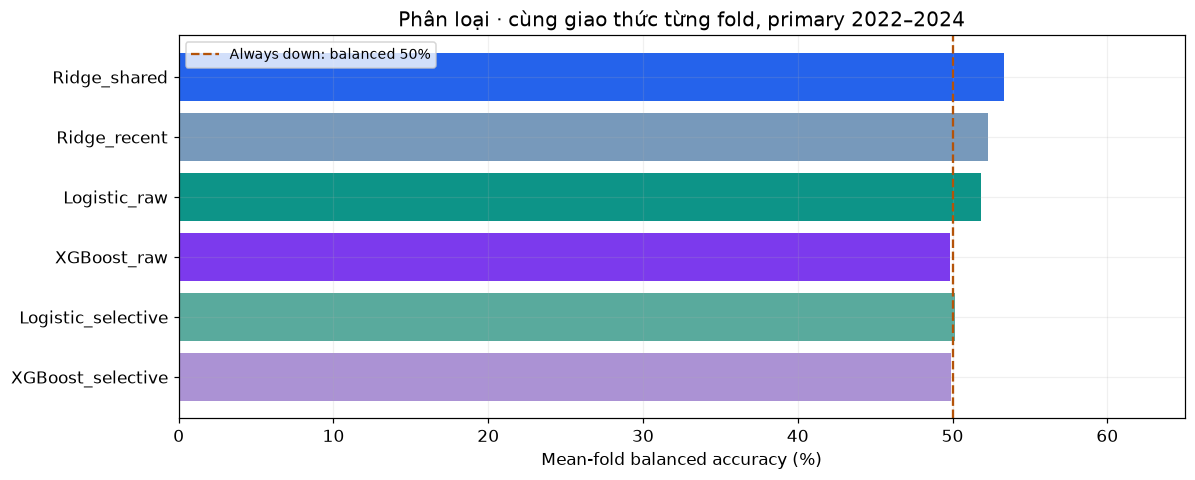

,mean_fold_balanced,mean_fold_coverage,worst_fold_balanced
strategy,,,
Ridge_shared,53.36,100.00,51.59
Ridge_recent,52.30,100.00,51.03
Logistic_raw,51.83,100.00,49.25
XGBoost_raw,49.82,100.00,47.06
Logistic_selective,50.16,100.00,50.00
XGBoost_selective,49.92,96.91,49.76


In [21]:
DIRECTION = ROOT/'reports/direction_selective/20261030T090621177786Z'
direction_metrics = read(DIRECTION/'metrics.csv')
direction_primary = read(DIRECTION/'primary_summary.csv').set_index('strategy')
direction_methods = ['Ridge_shared','Ridge_recent','Logistic_raw','XGBoost_raw','Logistic_selective','XGBoost_selective']
direction_primary = direction_primary.loc[direction_methods]
fig, ax = plt.subplots(figsize=(11,4.5))
ax.barh(direction_methods, direction_primary.mean_fold_balanced, color=['#2563eb','#7799bb','#0d9488','#7c3aed','#59aa9d','#ab92d4'])
ax.axvline(50,color='#b45309',ls='--',label='Always down: balanced 50%')
ax.set_xlim(0,65);ax.invert_yaxis();ax.set_xlabel('Mean-fold balanced accuracy (%)')
ax.set_title('Phân loại · cùng giao thức từng fold, primary 2022–2024')
ax.legend(fontsize=9);show('19_direction_primary')
display(direction_primary[['mean_fold_balanced','mean_fold_coverage','worst_fold_balanced']].round(2))

### Hit cao phải đọc cùng balanced và coverage
Sau sigmoid ở 2026, Logistic/XGBoost đều dự đoán giảm: 117/197 actual khác 0 là 59,39% Hit,
nhưng balanced chỉ 50%. Năm đó margin chọn bằng 0 nên bộ lọc chưa loại ngày nào.
Không tự tăng margin sau khi nhìn evaluation. Brier tốt hơn không tự chứng minh phân biệt hướng tốt hơn.

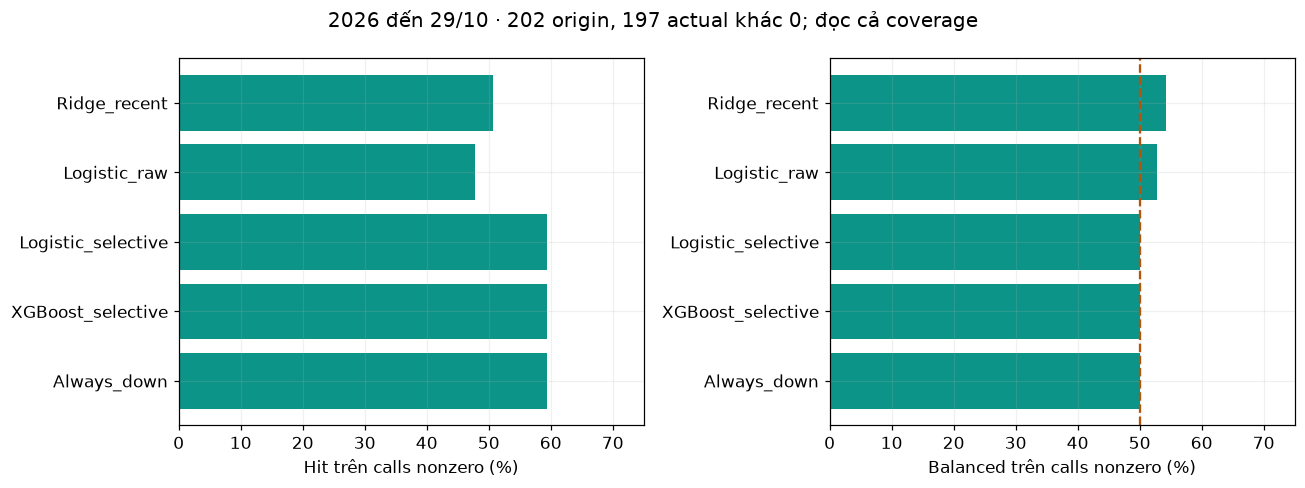

,n,calls_n,coverage_pct,hit_nonzero_called_pct,balanced_called_nonzero_pct
strategy,,,,,
Ridge_recent,202,202,100.0,50.76,54.20
Logistic_raw,202,202,100.0,47.72,52.82
Logistic_selective,202,202,100.0,59.39,50.00
XGBoost_selective,202,202,100.0,59.39,50.00
Always_down,202,202,100.0,59.39,50.00


,fold,model,margin,reason
0,eval_2022,Logistic,0.000,validation_balanced_accuracy_with_coverage_con...
1,eval_2022,XGBoost,0.025,validation_balanced_accuracy_with_coverage_con...
2,eval_2023,Logistic,0.000,validation_balanced_accuracy_with_coverage_con...
3,eval_2023,XGBoost,0.000,validation_balanced_accuracy_with_coverage_con...
4,eval_2024,Logistic,0.000,validation_balanced_accuracy_with_coverage_con...
5,eval_2024,XGBoost,0.000,validation_balanced_accuracy_with_coverage_con...
6,eval_2025,Logistic,0.000,validation_balanced_accuracy_with_coverage_con...
7,eval_2025,XGBoost,0.000,validation_balanced_accuracy_with_coverage_con...
8,eval_2026,Logistic,0.000,validation_balanced_accuracy_with_coverage_con...
9,eval_2026,XGBoost,0.000,validation_balanced_accuracy_with_coverage_con...


Kết luận: nhánh phân loại/selective chưa đủ căn cứ thay regression. Chi tiết threshold candidates, probability diagnostics và matched-day controls vẫn nằm trong thư mục study.

In [22]:
direction_2026 = direction_metrics.loc[direction_metrics.year.eq(2026)].set_index('strategy')
direction_2026 = direction_2026.loc[['Ridge_recent','Logistic_raw','Logistic_selective','XGBoost_selective','Always_down']]
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
for ax, column, title in zip(axes,['hit_nonzero_called_pct','balanced_called_nonzero_pct'],['Hit trên calls nonzero (%)','Balanced trên calls nonzero (%)']):
    ax.barh(direction_2026.index,direction_2026[column],color='#0d9488')
    ax.invert_yaxis();ax.set_xlim(0,75);ax.set_xlabel(title)
axes[1].axvline(50,color='#b45309',ls='--')
fig.suptitle('2026 đến 29/10 · 202 origin, 197 actual khác 0; đọc cả coverage')
show('20_direction_2026')
display(direction_2026[['n','calls_n','coverage_pct','hit_nonzero_called_pct','balanced_called_nonzero_pct']].round(2))
display(read(DIRECTION/'threshold_selection.csv')[['fold','model','margin','reason']])
display(Markdown('Kết luận: nhánh phân loại/selective chưa đủ căn cứ thay regression. Chi tiết threshold candidates, probability diagnostics và matched-day controls vẫn nằm trong thư mục study.'))

## 12. Gap mở cửa / thân nến: có cần đổi bộ feature không?
Phần này gom notebook ablation cũ. A giữ 6 return features; B thay Log_Return bằng
`log(Open_t / Close_previous_eligible)` và `log(Close_t / Open_t)`.
Hai thành phần cộng lại bằng Log_Return_t, đều đã biết sau đóng cửa origin; không dùng Open tương lai.
20 fit B so 20 artifact A trên cùng ngày/nhãn/hyperparameters. Không fit thêm trong notebook này.

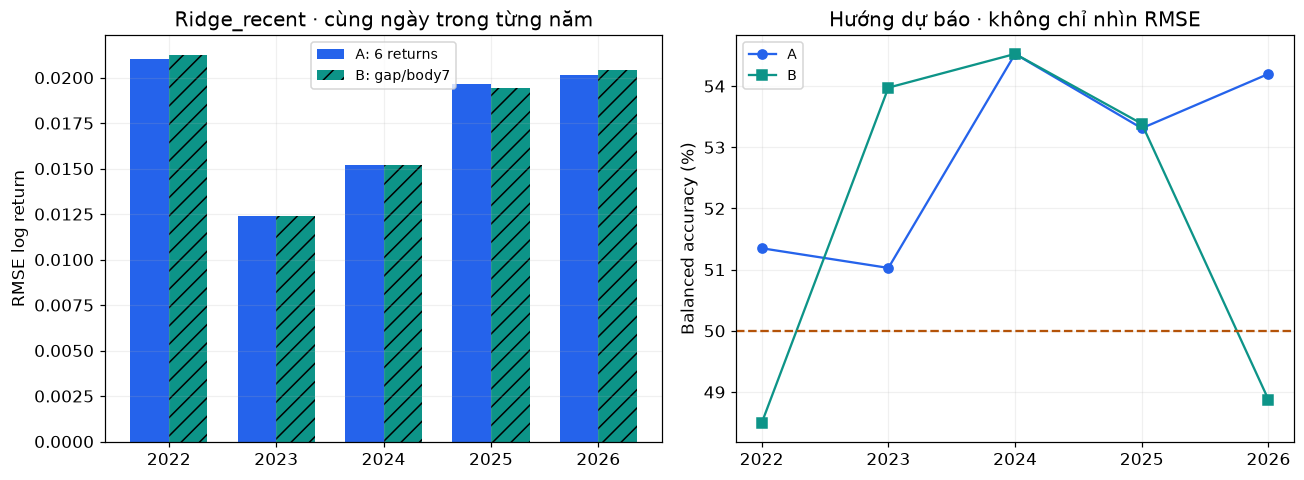

,case,strategy,mean_fold_balanced,mean_fold_hit_nonzero,mean_fold_called_accuracy,mean_fold_coverage,mean_fold_return_rmse,worst_fold_return_rmse
1,A_returns6,Logistic_raw,51.832609,55.005791,51.670121,100.0,NaN,NaN
3,A_returns6,Ridge_recent,52.300453,55.604921,52.209375,100.0,0.016219,0.021045
6,B_gap_body7,Logistic_raw,51.918327,55.170122,51.806149,100.0,NaN,NaN
8,B_gap_body7,Ridge_recent,52.330281,55.473912,52.074967,100.0,0.016293,0.021252


,case,n,nonzero_calls_n,return_rmse,price_mae_adjusted_vnd,hit_nonzero_called_pct,balanced_called_nonzero_pct
41,A_returns6,202,197,0.020119,1080.944044,50.761421,54.198718
46,B_gap_body7,202,197,0.020408,1096.733620,44.670051,48.872863


Kết luận: B chưa cải thiện ổn định. Primary Ridge RMSE tăng khoảng 0,46%; Logistic balanced tăng khoảng 0,09 điểm %. Năm 2026 Ridge B kém A về cả RMSE và hướng. Giữ A6; CI từng fold và tất cả lượt tốt/xấu vẫn được giữ trong evidence.

In [23]:
CANDLE = ROOT/'reports/candle_ablation/20261030T093521684942Z'
candle_metrics = read(CANDLE/'metrics.csv')
candle_primary = read(CANDLE/'primary_summary.csv')
candle_ridge = candle_metrics.loc[candle_metrics.strategy.eq('Ridge_recent')].pivot(index='year',columns='case',values='return_rmse')
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
positions = np.arange(len(candle_ridge))
axes[0].bar(positions-.18,candle_ridge.A_returns6,.36,label='A: 6 returns',color='#2563eb')
axes[0].bar(positions+.18,candle_ridge.B_gap_body7,.36,label='B: gap/body7',color='#0d9488',hatch='//')
axes[0].set_xticks(positions,candle_ridge.index);axes[0].set_ylabel('RMSE log return')
axes[0].set_title('Ridge_recent · cùng ngày trong từng năm');axes[0].legend(fontsize=9)
candle_direction = candle_metrics.loc[candle_metrics.strategy.eq('Ridge_recent')].pivot(index='year',columns='case',values='balanced_called_nonzero_pct')
axes[1].plot(candle_direction.index,candle_direction.A_returns6,marker='o',label='A',color='#2563eb')
axes[1].plot(candle_direction.index,candle_direction.B_gap_body7,marker='s',label='B',color='#0d9488')
axes[1].set_xticks(candle_direction.index)
axes[1].axhline(50,color='#b45309',ls='--');axes[1].set_ylabel('Balanced accuracy (%)')
axes[1].set_title('Hướng dự báo · không chỉ nhìn RMSE');axes[1].legend(fontsize=9)
show('21_gap_body_comparison')
display(candle_primary.loc[candle_primary.strategy.isin(['Ridge_recent','Logistic_raw'])].round(6))
display(candle_metrics.loc[candle_metrics.year.eq(2026)&candle_metrics.strategy.eq('Ridge_recent'),
    ['case','n','nonzero_calls_n','return_rmse','price_mae_adjusted_vnd','hit_nonzero_called_pct','balanced_called_nonzero_pct']].round(6))
display(Markdown('Kết luận: B chưa cải thiện ổn định. Primary Ridge RMSE tăng khoảng 0,46%; Logistic balanced tăng khoảng 0,09 điểm %. Năm 2026 Ridge B kém A về cả RMSE và hướng. Giữ A6; CI từng fold và tất cả lượt tốt/xấu vẫn được giữ trong evidence.'))

Nguồn hai phần cuối: `reports/direction_selective/20261030T090621177786Z/`
và `reports/candle_ablation/20261030T093521684942Z/`.
Đọc `metrics.csv`, `primary_summary.csv`, threshold/paired-effect CSV, protocol/manifest và
`reports/training_history/research_notes.json` để tra diễn giải đầy đủ từ notebook/báo cáo cũ.
Không dùng các bảng này để gán thành tích cho bundle train đến 29/10 đang chạy API.

## Kết luận để trình bày với team
1. Tái lập CPU–Colab xác minh pipeline và artifact; không đồng nghĩa dự báo chính xác hơn.
2. Các nghiên cứu tiếp theo đã đối chứng seed/features/nguồn dữ liệu; giữ cả kết quả tốt và xấu.
3. Nhãn/cohort đổi thì metric cũ và mới không so trực tiếp. Các biểu đồ trên được tách theo giao thức.
4. Vietcap là nguồn dữ liệu nghiên cứu và bundle Ridge local hiện tại; baseline vẫn cần giữ. Phần 2026 tới 29/10 đã được mở để đánh giá hồi cứu, không còn là holdout chưa xem.
5. Mọi lần cải thiện tiếp phải khóa protocol trước fit và chọn bằng validation; không chọn theo điểm evaluation đẹp nhất.
6. Phân tích lỗi và Ridge refinement được bổ sung ở phần 7–8; cải thiện nhỏ về RMSE chưa đồng nghĩa ổn định ở mọi fold hoặc hơn baseline.
7. Phần 9 cho thấy các model đóng băng chưa vượt Zero Return năm 2026; cần xử lý nguồn/recency/bias và có đánh giá tương lai mới, không tune lại trên 2026 rồi gọi là holdout độc lập.
8. Phần 10: recency giúp so bản cũ; bias cải thiện một số metric nhưng không ổn định ở mọi phương án. Edge hồi quy vs Zero rất nhỏ, CI chứa 0; giữ serving và theo dõi shadow phía trước.
9. Phần 11–12: classifier/selective và gap/body chưa tạo cải thiện ổn định để thay Ridge6. Giữ kết quả âm và đọc cùng baseline, coverage, CI.

Chi tiết: `TRAINING_HISTORY.md`, `reports/source_comparison/20261029T142732805710Z/metrics.csv`. Notebook là bản tổng hợp bằng chứng, không phải khuyến nghị giao dịch.